In [6]:
import ast
import os
import optuna
import ipynbname
import pandas as pd
import numpy as np
from optuna.exceptions import TrialPruned
from Functions.AutoCloud_V4_2 import *
from Functions.Utils import *
from Functions.Graphs import *
from Functions.TedaGraphs import *
from Functions.Utils_OPT_R2 import *

FileName = ipynbname.name()

# Configuração do experimento
FEEDBACK = 'symmetric'      # 'symmetric' (gradiente no passo atual) ou 'random' (ablação: RFLO + DFA)
WTAG, WTAP = False, False   # configuração principal: soma ponderada dos grânulos (eq. 36)
EOL = 0.3                   # limiar de fim de vida (EoL) do HI

# rho dinâmico (AutoCloud_V4_2): começa em 0 e é ajustado a cada iteração maximizando V = média(cov)*média(sp)
RHO_TARGET = 'RUL'           # 'HI' (causal, HI um passo à frente) ou 'RUL' (oráculo: usa a RUL real; n_rho previsões por passo)
RHO_MIN, RHO_MAX, N_RHO = 1e-3, 1e-2, 4   # grade log-espaçada de candidatos
LAM = 1.0                   # fator de esquecimento (1.0 = todos os passos com o mesmo peso)

def RunTag(feedback=None, wtaG=None, wtaP=None):
    # Uma pasta de resultados por configuração (feedback, wtaG, wtaP)
    feedback = FEEDBACK if feedback is None else feedback
    wtaG = WTAG if wtaG is None else wtaG
    wtaP = WTAP if wtaP is None else wtaP
    return f'{FileName}_{feedback}_G{int(wtaG)}P{int(wtaP)}'

def RefEoL(sig, eol, nI, mO, mode):
    '''
    Referência da RUL real baseada no limiar de EoL (eq. 12): RUL_real = iEoL - k_dado.
    O AutoCloud calcula rulR = ref - k, com k = j + 2 na iteração j, e o PrepareData
    alinha a iteração j à amostra k_dado = k0 + j. Logo ref = iEoL - k0 + 2.
    Retorna ref e J, o número de iterações com RUL real >= 1.
    '''
    sig = np.asarray(sig, dtype=float)
    if not np.any(sig <= eol): raise ValueError('O HI nunca atinge o limiar de EoL.')
    iEoL = int(np.argmax(sig <= eol))
    k0 = (max(nI, 1, mO) if mode in ('ahead', 1) else max(nI, 1)) - 1
    return iEoL - k0 + 2, iEoL - k0

def nOMax(sig, eol):
    '''
    Maior nO (modo 'ahead') para o qual o fluxo do PrepareData alcança a última amostra antes do EoL.
    A última janela fica em k = K - nO - 2 (o PrepareData descarta a última); exigir k >= iEoL - 1
    dá nO <= K - iEoL - 1, independente de nI e mO. No modo 'past' o fluxo sempre alcança o EoL.
    '''
    sig = np.asarray(sig, dtype=float)
    return len(sig) - int(np.argmax(sig <= eol)) - 1

out_path = os.path.join('Optimization', RunTag(), 'multi', 'Optimization.csv')
dfs = [pd.read_csv(out_path)] if os.path.exists(out_path) else []
RS = pd.read_excel(r'Dataset\RS.xlsx')
HI = pd.read_excel(r'Dataset\HI.xlsx')
sig = HI['PC1'].values

rho dinâmico (RUL): final = 1.000e-03 | V (último passo) = 0.2418 | Vsum = 19.4741
HI  (corrida completa): cov=0.7093 | sp=0.9769 | V=0.6940
RUL (corrida completa): cov=0.9302 | sp=0.1655 | V=0.0958


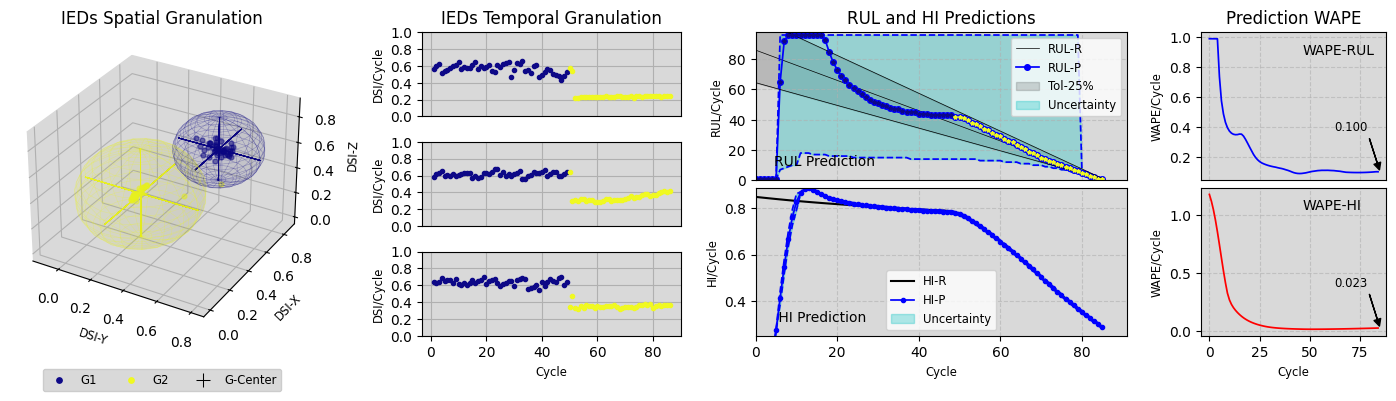

In [7]:
params = [3.5,28,[70],8,0,1,2,5,19,1,0]
m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

# rho dinâmico: não é mais informado; começa em 0 e é atualizado a cada iteração (maximiza V)
teda=AutoCloud(m=m,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
               tau=τ,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO,
               rho_target=RHO_TARGET,rho_min=RHO_MIN,rho_max=RHO_MAX,n_rho=N_RHO,lam=LAM)

for j,_ in enumerate(X[:J]):
    teda.run(X[j])
    teda.RUL_Prediction(Y[j],mode='interval',lim=len(sig)-nI+1,show=False)
    teda.WAPE_HI2(Y[j],Z[j])
    teda.Adapt(Y[j],Z[j])

print(f'rho dinâmico ({RHO_TARGET}): final = {teda.rho:.3e} | V (último passo) = {teda.V:.4f} | Vsum = {teda.Vsum:.4f}')
teda.HI_Granularity()
print(f'HI  (corrida completa): cov={teda.cov:.4f} | sp={teda.sp:.4f} | V={teda.V:.4f}')
teda.RUL_Granularity()
print(f'RUL (corrida completa): cov={teda.cov:.4f} | sp={teda.sp:.4f} | V={teda.V:.4f}')
PlotDSI_3D_PLT(teda,xi=0)


In [ ]:
# Evolução do rho dinâmico (usado na predição de cada passo), de V e do acumulado Vsum
PlotSeriesPLY(ySeries=[teda.rho_hist], names=['rho'], title='rho dinâmico por iteração')
PlotSeriesPLY(ySeries=[teda.V_hist, teda.Vsum_hist], names=['V','Vsum'], title='V e Vsum por iteração')
PlotSeriesPLY(xSeries=[list(teda.rho_grid)], ySeries=[teda.V_grid], names=['V(rho)'], title='V(rho) dos candidatos no último passo')

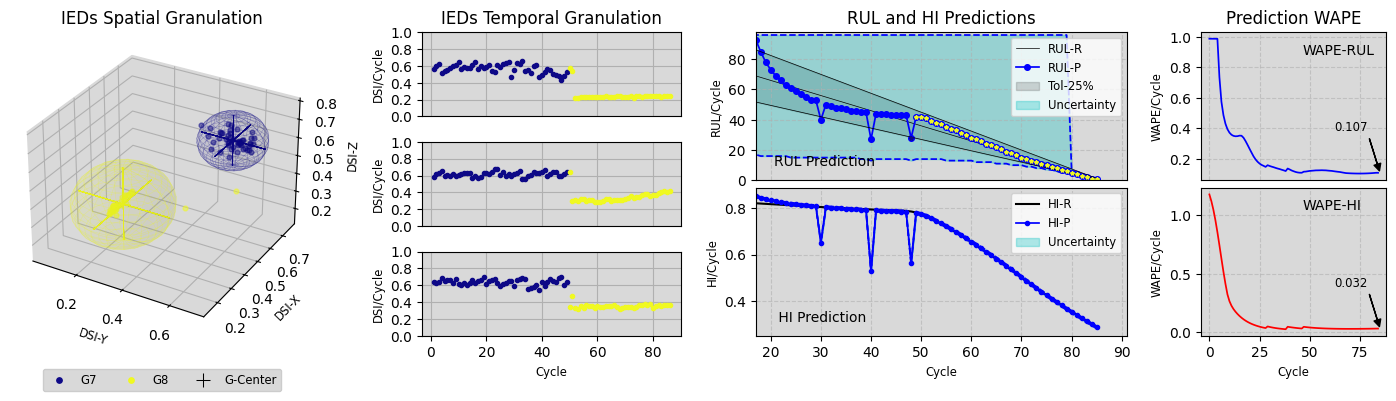

In [8]:
m,nI,nR,nO,mO,N1,N2,N3,τ,mode,act = params
X, Y, Z = PrepareData(RS, HI, nI, nO, mO, 1, mode)
ref, J = RefEoL(sig, EOL, nI, mO, mode)
if len(X) < J: print(f'Aviso: nO={nO} > {nOMax(sig, EOL)}: o fluxo termina antes do EoL (última RUL real = {J-len(X)+1}).')
nI = len(Y[0])
if isinstance(nR, str): nR = ast.literal_eval(nR)

teda=AutoCloud(m=2,nI=nI,nR=nR,nO=nO+mO,ηS=[N1,N2,N3],mode=mode,act=act,
               tau=τ,eol=EOL,ref=ref,wtaG=WTAG,wtaP=WTAP,feedback=FEEDBACK,mO=mO,
               rho_target=RHO_TARGET,rho_min=RHO_MIN,rho_max=RHO_MAX,n_rho=N_RHO,lam=LAM) 


for j,_ in enumerate(X[:J]):
    teda.run(X[j])
    teda.RUL_Prediction(Y[j],mode='interval',lim=len(sig)-nI+1,show=False)
    teda.WAPE_HI2(Y[j],Z[j])
    teda.Adapt(Y[j],Z[j])

#teda.c = np.append(teda.c,teda.gm)  
PlotDSI_3D_PLT(teda)

In [ ]:
PlotSeriesPLY(ySeries=[teda.rulR,teda.rulP,teda.rulL,teda.rulU],names=['real','pred','predL','predU'])


In [ ]:
#PlotSeriesPLY(ySeries=[teda.hiR,teda.hiP,teda.hiL,teda.hiU])
PlotSeriesPLY(ySeries=[teda.hiP-teda.hiL,teda.hiU-teda.hiP])

#PlotSeriesPLY(ySeries=[teda.rulR,teda.rulP,teda.rulL,teda.rulU])

In [ ]:
print('rulP:',teda.rulP)
print('rulL:',teda.rulL)
print('rulU:',teda.rulU)

# Coerência dos intervalos (eRNN_GD_R3: aritmética intervalar exata) e truncamento em lim
n = len(teda.rulP)
print(f"\nHI : hiP fora de [hiL, hiU]  : {int(np.sum((teda.hiP < teda.hiL) | (teda.hiP > teda.hiU)))}/{len(teda.hiP)}")
print(f"RUL: rulP fora de [rulL, rulU]: {int(np.sum((teda.rulP < teda.rulL) | (teda.rulP > teda.rulU)))}/{n}")
print(f"RUL truncada em lim (não atinge o EoL) -> inferior: {teda.rulCapL.sum()}/{n} | pontual: {teda.rulCapP.sum()}/{n} | superior: {teda.rulCapU.sum()}/{n}")